# Predicting the 2026 Israeli Knesset election
### Weekly poll averages + a Kalman filter per party

Election day: **Tuesday, 27 October 2026** — 120 seats, 3.25% electoral threshold (אחוז חסימה).

**Pipeline**
1. Load 184 published polls (26 Apr – 23 Oct 2026) and convert each poll's seat projection back to **vote share (%)**.
2. Estimate and remove each pollster's **house effect** (systematic lean).
3. **Average the polls by week** (Israeli week, Sun–Sat).
4. Fit a **local-level Kalman filter** to each party's weekly series.
5. Forecast election week, **simulate** the election, apply the **3.25% threshold** and allocate 120 seats by **D'Hondt (Bader-Ofer)**.

Data: [Middle East Forum – Israel Election 2026 Poll of Polls](https://israelvote.meforum.org/polls/), plus the final 23 Oct polls (Kan 11, Channel 12, Channel 13) as reported by Times of Israel and Ynet.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.optimize import minimize

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
%matplotlib inline

## Settings
`BLOCS` follows the usual Israeli split: Netanyahu's coalition parties vs. the Jewish opposition parties vs. the Arab parties.

In [2]:
PARTIES = ['Likud', 'Yashar', 'Together', 'Democrats', 'JointList', 'Otzma', 'Shas',
           'UTJ', 'YisraelBeiteinu', 'RelZionism', 'Raam', 'Amcha', 'Reservists', 'BlueWhite']
HE = {'Likud': 'הליכוד', 'Yashar': 'ישר!', 'Together': 'ביחד', 'Democrats': 'הדמוקרטים',
      'JointList': 'הרשימה המשותפת', 'Otzma': 'עוצמה יהודית', 'Shas': 'ש"ס', 'UTJ': 'יהדות התורה',
      'YisraelBeiteinu': 'ישראל ביתנו', 'RelZionism': 'הציונות הדתית', 'Raam': 'רע"מ',
      'Amcha': 'עמך ישראל', 'Reservists': 'המילואימניקים', 'BlueWhite': 'כחול לבן'}
BLOCS = {'Netanyahu bloc': ['Likud', 'Otzma', 'Shas', 'UTJ', 'RelZionism'],
         'Opposition (Jewish parties)': ['Yashar', 'Together', 'Democrats', 'YisraelBeiteinu',
                                          'Reservists', 'BlueWhite'],
         'Arab parties': ['JointList', 'Raam']}

START     = '2026-04-26'                  # first week in which the "Together" list (Bennett + Lapid) is polled
ELECTION  = pd.Timestamp('2026-10-27')
THRESH    = 3.25                          # electoral threshold, % of valid votes
SHRINK    = 3                             # house-effect shrinkage (pseudo-polls with zero effect)
EXTRA_ERR = 0.8                           # extra election-day polling error per party (% points, sd)
BLOC_ERR  = 2.0                           # shared polling error between the two blocs (% points, sd)
N_SIMS    = 5000
DATA, OUT = 'data/israel_polls_2026.csv', 'outputs/'

## 1. Load the polls

Each row is one published poll. Pollsters report **seats** for parties that pass the threshold and a **percentage in brackets**, e.g. `(2.8%)`, for parties below it. `.` means the party was not included in that poll.

In [3]:
raw = pd.read_csv(DATA, dtype=str)
raw['date'] = pd.to_datetime(raw['date'])
raw = raw[raw.date >= START].reset_index(drop=True)
raw['house'] = raw.pollster.replace({'Midgam': 'Midgam R&C'})   # same firm, two labels
raw['week'] = raw.date.dt.to_period('W-SAT')                     # Israeli week: Sunday–Saturday
print(len(raw), 'polls from', raw.date.min().date(), 'to', raw.date.max().date())
raw.head()

184 polls from 2026-04-26 to 2026-10-22


,date,pollster,outlet,n,Likud,Yashar,Together,Democrats,JointList,Otzma,Shas,UTJ,YisraelBeiteinu,RelZionism,Raam,Amcha,BlueWhite,Reservists,Other,Gov,house,week
0,2026-10-22,Madad,Channel 13,1875,19,22,14,10,9,8,7,8,8,8,7,.,.,.,NaN,50,Madad,2026-10-18/2026-10-24
1,2026-10-22,Midgam,HaHadashot 12,1018,21,23,15,10,9,8,8,7,8,6,5,.,.,.,NaN,50,Midgam R&C,2026-10-18/2026-10-24
2,2026-10-22,Kantar,Kan 11,1106,20,22,14,8,9,8,7,8,8,7,5,.,.,4,NaN,50,Kantar,2026-10-18/2026-10-24
3,2026-10-21,Midgam R&C,HaHadashot 12,505,19,23,15,9,9,7,8,7,8,6,5,4,.,(2.8%),NaN,47,Midgam R&C,2026-10-18/2026-10-24
4,2026-10-21,Midgam Project,Channel 13,1084,19,20,14,10,9,7,7,8,8,8,6,(3.2%),.,4,NaN,49,Midgam Project,2026-10-18/2026-10-24


### Sanity check
The `Gov` column is the coalition total reported by the source. It should equal Likud + Otzma + Shas + UTJ + Religious Zionism in every poll.

In [4]:
def parse(v):
    '''cell -> (seats, below-threshold %). NaN where the party was not polled.'''
    if pd.isna(v) or v.strip() in ('.', ''):
        return np.nan, np.nan
    m = re.match(r'\(<?([\d.]+)%\)', v.strip())
    return (0.0, float(m.group(1))) if m else (float(v), np.nan)

SEATS = raw[PARTIES].apply(lambda c: c.map(lambda v: parse(v)[0]))
BELOW = raw[PARTIES].apply(lambda c: c.map(lambda v: parse(v)[1]))

gov_calc = SEATS[BLOCS['Netanyahu bloc']].sum(axis=1)
print('coalition-total mismatches:', int((gov_calc != raw.Gov.astype(float)).sum()))

coalition-total mismatches: 0


## 2. Seats → vote share (%)

Seats are handed out only among parties that pass the threshold, so the votes of failed parties are "wasted":

$$\text{share}_i = \frac{\text{seats}_i}{120}\,\big(100 - \text{wasted}\big), \qquad \text{wasted} = \sum_{j\ \text{below threshold}} \%_j$$

Parties under the threshold keep their reported %.

Until late August the Arab lists (Hadash-Ta'al, Balad) ran separately and the table has no Joint List column. For those polls Joint List seats = 120 − the seats of all the other parties.

In [5]:
jl_missing = SEATS.JointList.isna()
SEATS.loc[jl_missing, 'JointList'] = 120 - SEATS.loc[jl_missing].drop(columns='JointList').sum(axis=1)

wasted = BELOW.sum(axis=1)
Y = SEATS.div(120).mul(100 - wasted, axis=0)     # parties with seats
Y = Y.where(SEATS != 0, BELOW)                   # parties below the threshold: reported %
raw['wasted_pct'] = wasted

print(f'average wasted vote in polls: {wasted.mean():.2f}%')
Y.assign(date=raw.date.dt.date, pollster=raw.pollster).set_index(['date', 'pollster']).round(2).head()

average wasted vote in polls: 1.89%


Likud  Yashar  Together  Democrats  JointList  Otzma  Shas   UTJ  YisraelBeiteinu  RelZionism  Raam  Amcha  Reservists  BlueWhite
date       pollster                                                                                                                                         
2026-10-22 Madad           15.83   18.33     11.67       8.33       7.50   6.67  5.83  6.67             6.67        6.67  5.83    NaN         NaN        NaN
           Midgam          17.50   19.17     12.50       8.33       7.50   6.67  6.67  5.83             6.67        5.00  4.17    NaN         NaN        NaN
           Kantar          16.67   18.33     11.67       6.67       7.50   6.67  5.83  6.67             6.67        5.83  4.17    NaN        3.33        NaN
2026-10-21 Midgam R&C      15.39   18.63     12.15       7.29       7.29   5.67  6.48  5.67             6.48        4.86  4.05   3.24        2.80        NaN
           Midgam Project  15.33   16.13     11.29       8.07       7.26   5.65  5.65  6.45             6.45        6.45  4.84   3.20        3.23        NaN

## 3. House effects

Some pollsters lean consistently (e.g. Channel 14's pollster gives Likud several points more than everyone else). If we average naively, the weekly average jumps depending on *which* pollsters published that week.

Iterate: weekly mean of the adjusted polls → each pollster's average deviation from it (shrunk toward 0) → re-centre so the average poll has zero bias.

> Assumption: the **average pollster is unbiased**. If the right-leaning pollsters turn out to be correct, this correction will under-estimate the Netanyahu bloc.

In [6]:
house = pd.DataFrame(0.0, index=sorted(raw.house.unique()), columns=PARTIES)
for _ in range(10):
    adj = Y - house.loc[raw.house].values
    wk_mean = adj.groupby(raw.week).transform('mean')
    g = (Y - wk_mean).groupby(raw.house)
    house = g.sum() / (g.count() + SHRINK)
    w = raw.house.value_counts().reindex(house.index)
    house = house - house.mul(w, axis=0).sum() / w.sum()
adjY = Y - house.loc[raw.house].values

print('House effects, % points (+ = pollster gives the party more than average):')
house[['Likud', 'Yashar', 'Together', 'Democrats', 'Otzma', 'Shas', 'YisraelBeiteinu']].round(1)

House effects, % points (+ = pollster gives the party more than average):


,Likud,Yashar,Together,Democrats,Otzma,Shas,YisraelBeiteinu
house,,,,,,,
Direct Polls,3.2,-0.7,-2.2,0.2,-0.0,0.0,-0.5
Filber,5.5,-0.8,-4.0,-0.3,-0.4,1.4,-1.1
Kantar,-1.0,0.3,0.6,-0.2,0.5,-0.4,-0.0
Lazar,-2.1,0.3,1.8,0.2,0.2,-0.6,0.4
Maagar Mochot,-0.8,-0.7,1.1,-0.1,0.8,0.5,-0.5
Madad,-0.4,0.1,0.2,0.3,0.1,-0.2,0.1
Midgam Project,-2.0,-0.5,0.3,0.6,0.0,-0.5,0.4
Midgam R&C,-1.4,0.6,1.2,0.5,-0.1,-0.3,0.1
Yossi Tatika,-1.6,0.7,1.4,-1.1,-0.6,0.5,0.9


## 4. Weekly averages

In [7]:
weeks  = pd.period_range(raw.week.min(), ELECTION.to_period('W-SAT'), freq='W-SAT')   # last week = election week
wk_avg = adjY.groupby(raw.week).mean().reindex(weeks)     # house-adjusted
wk_raw = Y.groupby(raw.week).mean().reindex(weeks)        # raw, for comparison
wk_n   = adjY.groupby(raw.week).count().reindex(weeks).fillna(0)

tbl = wk_avg.copy(); tbl.index = tbl.index.start_time.date
tbl.insert(0, 'n_polls', wk_n.max(axis=1).values.astype(int))
tbl.round(1).tail(8)

,n_polls,Likud,Yashar,Together,Democrats,JointList,Otzma,Shas,UTJ,YisraelBeiteinu,RelZionism,Raam,Amcha,Reservists,BlueWhite
2026-09-06,12,18.3,18.9,9.5,7.5,5.7,5.9,6.2,6.2,6.4,4.6,4.1,3.1,2.7,1.1
2026-09-13,9,17.9,18.1,9.7,7.4,6.0,6.2,6.2,6.2,6.5,5.0,4.1,3.4,2.8,1.0
2026-09-20,4,17.7,18.5,9.2,7.9,5.9,6.2,5.9,6.2,6.7,4.8,4.3,3.3,2.9,1.2
2026-09-27,4,18.3,18.0,8.9,7.8,6.1,6.4,6.1,6.1,6.9,4.7,4.1,3.3,2.7,0.9
2026-10-04,4,18.2,17.2,9.7,7.3,6.2,6.5,6.0,6.3,6.6,5.1,4.3,2.8,3.0,1.2
2026-10-11,7,17.6,17.4,9.8,7.3,6.5,6.6,6.3,6.5,6.5,4.9,4.4,2.9,3.1,1.2
2026-10-18,10,17.4,17.8,10.8,7.2,6.9,6.5,6.5,6.0,6.2,5.6,4.5,2.9,2.9,1.6
2026-10-25,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Kalman filter (local-level model)

For each party, the true support $x_t$ is a random walk and the weekly average $y_t$ is a noisy measurement of it:

$$x_t = x_{t-1} + w_t,\quad w_t \sim N(0, q) \qquad\qquad y_t = x_t + v_t,\quad v_t \sim N\!\left(0, \tfrac{r}{n_t}\right)$$

- $n_t$ — number of polls that week (more polls → more precise average; weeks with no polls are simply skipped by the update step).
- $r$ — per-poll noise. Polls in the same week measure the same thing, so $r$ is the pooled **within-week variance** of the adjusted polls.
- $q$ — how fast true support drifts. Estimated by **maximum likelihood** (prediction-error decomposition).

The filter gives the real-time estimate; the **Rauch-Tung-Striebel smoother** gives the best estimate of the past path (used in the plots). The forecast is the one-step-ahead prediction for election week.

In [8]:
def kalman(y, n, q, r, smooth=False):
    T = len(y)
    x_f, P_f, x_p, P_p = np.zeros(T), np.zeros(T), np.zeros(T), np.zeros(T)
    first = np.flatnonzero(~np.isnan(y))[0]
    x, P = y[first], 10.0                      # vague prior (% points^2)
    ll = 0.0
    for t in range(T):
        xp, Pp = x, P + q                      # predict
        x_p[t], P_p[t] = xp, Pp
        if not np.isnan(y[t]) and n[t] > 0:    # update
            S = Pp + r / n[t]
            K = Pp / S
            e = y[t] - xp
            x, P = xp + K * e, (1 - K) * Pp
            if t > first:
                ll += -0.5 * (np.log(2 * np.pi * S) + e * e / S)
        else:
            x, P = xp, Pp
        x_f[t], P_f[t] = x, P
    if not smooth:
        return x_f, P_f, ll
    xs, Ps = x_f.copy(), P_f.copy()            # RTS smoother
    for t in range(T - 2, -1, -1):
        C = P_f[t] / P_p[t + 1]
        xs[t] = x_f[t] + C * (xs[t + 1] - x_p[t + 1])
        Ps[t] = P_f[t] + C * C * (Ps[t + 1] - P_p[t + 1])
    return x_f, P_f, xs, Ps, ll


def fit_q(y, n, r):
    '''maximum-likelihood estimate of the drift variance q (r held fixed)'''
    obj = lambda th: -kalman(y, n, np.exp(th[0]), r)[2]
    best = min((minimize(obj, [x0], method='Nelder-Mead') for x0 in np.log([.01, .1, 1])),
               key=lambda o: o.fun)
    return float(np.exp(best.x[0]))


# per-poll noise r: pooled within-week variance (unbiased)
dev = adjY - adjY.groupby(raw.week).transform('mean')
cnt = adjY.groupby(raw.week).transform('count')
R_POLL = (dev ** 2).where(cnt > 1).sum() / (cnt.where(cnt > 1) - 1).div(cnt).sum()

In [9]:
results, paths = [], {}
for p in PARTIES:
    y = wk_avg[p].values.astype(float)
    n = wk_n[p].values.astype(float)
    r = float(R_POLL[p])
    q = fit_q(y, n, r)
    x_f, P_f, xs, Ps, ll = kalman(y, n, q, r, smooth=True)
    mu, sd = x_f[-1], np.sqrt(P_f[-1])          # election week has no polls -> 1-step-ahead forecast
    results.append(dict(party=p, forecast=mu, sd=sd, lo80=mu - 1.2816 * sd, hi80=mu + 1.2816 * sd,
                        q=q, r=r, last_week_raw=wk_raw[p].dropna().iloc[-1], n_polls=int(n.sum())))
    first = np.flatnonzero(np.isfinite(y))[0]
    xs, Ps = xs.copy(), Ps.copy(); xs[:first] = np.nan; Ps[:first] = np.nan   # party not polled yet
    paths[p] = dict(y=y, raw=wk_raw[p].values, s=xs, Ps=Ps)

res = pd.DataFrame(results).set_index('party')
res[['forecast', 'sd', 'lo80', 'hi80', 'last_week_raw', 'q', 'r', 'n_polls']].sort_values('forecast', ascending=False).round(2)

,forecast,sd,lo80,hi80,last_week_raw,q,r,n_polls
party,,,,,,,,
Yashar,17.76,0.74,16.81,18.71,17.88,0.48,0.75,184
Likud,17.47,0.50,16.83,18.10,16.96,0.19,0.76,184
Together,10.69,0.83,9.63,11.75,11.09,0.60,0.92,184
Democrats,7.28,0.20,7.01,7.54,7.44,0.02,0.31,184
JointList,6.70,0.40,6.19,7.21,6.96,0.10,0.86,184
Otzma,6.46,0.22,6.19,6.74,6.55,0.02,0.37,184
Shas,6.40,0.18,6.17,6.64,6.22,0.02,0.16,184
YisraelBeiteinu,6.27,0.32,5.85,6.68,6.23,0.08,0.25,184
UTJ,6.14,0.14,5.97,6.32,6.07,0.01,0.12,184


## 6. Threshold + seat allocation, and election simulation

**Point forecast:** normalise the forecast shares to 100%, drop parties under 3.25%, allocate 120 seats with D'Hondt (Israel's Bader-Ofer method; surplus-vote agreements are ignored).

**Simulation** — 5,000 elections. Each draws every party's share from the Kalman forecast distribution plus:
- an extra per-party election-day error (`EXTRA_ERR`),
- a **shared bloc error** (`BLOC_ERR`): Israeli polls tend to miss by bloc, so votes move between the Netanyahu bloc and the Jewish opposition together.

Then: threshold → D'Hondt → seats.

In [10]:
def dhondt(votes, seats=120, thresh=THRESH):
    votes = np.where(votes >= thresh, votes, 0.0)
    alloc = np.zeros(len(votes), int)
    for _ in range(seats):
        alloc[np.argmax(votes / (alloc + 1))] += 1
    return alloc

res['forecast_norm'] = res.forecast / res.forecast.sum() * 100
res['predicted_seats'] = dhondt(res.forecast_norm.values)

rng = np.random.default_rng(2026)
f = res.forecast.values
draws = rng.normal(f, np.sqrt(res.sd.values ** 2 + EXTRA_ERR ** 2), size=(N_SIMS, len(res)))
right = res.index.isin(BLOCS['Netanyahu bloc'])
opp   = res.index.isin(BLOCS['Opposition (Jewish parties)'])
shock = rng.normal(0, BLOC_ERR, size=(N_SIMS, 1))
draws += shock * np.where(right, f / f[right].sum(), 0) - shock * np.where(opp, f / f[opp].sum(), 0)
draws = np.clip(draws, 0, None)
draws = draws / draws.sum(axis=1, keepdims=True) * 100

sim = pd.DataFrame([dhondt(d) for d in draws], columns=res.index)
res['vote_lo80'] = np.quantile(draws, .1, axis=0)
res['vote_hi80'] = np.quantile(draws, .9, axis=0)
res['seats_median'] = sim.median()
res['seats_lo80'] = sim.quantile(.1)
res['seats_hi80'] = sim.quantile(.9)
res['p_pass_threshold'] = (draws >= THRESH).mean(axis=0)
res = res.sort_values('forecast', ascending=False)

res.assign(name=[HE[p] for p in res.index])[
    ['name', 'forecast_norm', 'vote_lo80', 'vote_hi80', 'predicted_seats', 'seats_lo80', 'seats_hi80', 'p_pass_threshold']
].round(2)

,name,forecast_norm,vote_lo80,vote_hi80,predicted_seats,seats_lo80,seats_hi80,p_pass_threshold
party,,,,,,,,
Yashar,ישר!,17.39,15.76,19.03,23,20.0,25.0,1.00
Likud,הליכוד,17.10,15.47,18.67,22,20.0,24.0,1.00
Together,ביחד,10.47,8.99,11.97,14,11.0,15.0,1.00
Democrats,הדמוקרטים,7.12,6.02,8.21,9,7.0,10.0,1.00
JointList,הרשימה המשותפת,6.56,5.44,7.67,8,7.0,10.0,1.00
Otzma,עוצמה יהודית,6.33,5.22,7.40,8,6.0,9.0,1.00
Shas,"ש""ס",6.27,5.20,7.31,8,6.0,9.0,1.00
YisraelBeiteinu,ישראל ביתנו,6.13,5.04,7.23,8,6.0,9.0,1.00
UTJ,יהדות התורה,6.01,4.95,7.07,8,6.0,9.0,1.00


In [11]:
rows = []
for b, members in BLOCS.items():
    tot = sim[members].sum(axis=1)
    rows.append(dict(bloc=b, predicted_seats=int(res.loc[members, 'predicted_seats'].sum()),
                     median=tot.median(), lo80=tot.quantile(.1), hi80=tot.quantile(.9),
                     p_61_plus=(tot >= 61).mean()))
blocs = pd.DataFrame(rows).set_index('bloc')
print('total seats:', res.predicted_seats.sum())
blocs.round(3)

total seats: 120


,predicted_seats,median,lo80,hi80,p_61_plus
bloc,,,,,
Netanyahu bloc,53,52.0,47.0,56.0,0.009
Opposition (Jewish parties),54,54.0,49.0,58.0,0.030
Arab parties,13,13.0,11.0,15.0,0.000


## 7. Charts (Hebrew labels)

Matplotlib ≥ 3.11 lays out right-to-left text itself. Older versions draw Hebrew reversed, so in that case the text is reordered with `python-bidi`.

In [12]:
from packaging.version import Version
if Version(matplotlib.__version__) >= Version('3.11'):
    h = lambda t: t
else:
    from bidi import get_display as h          # pip install python-bidi
plt.rcParams['font.family'] = 'DejaVu Sans'    # has Hebrew glyphs
INK, MUTED, ACC = '#1f2328', '#8a8f98', '#2a6fdb'

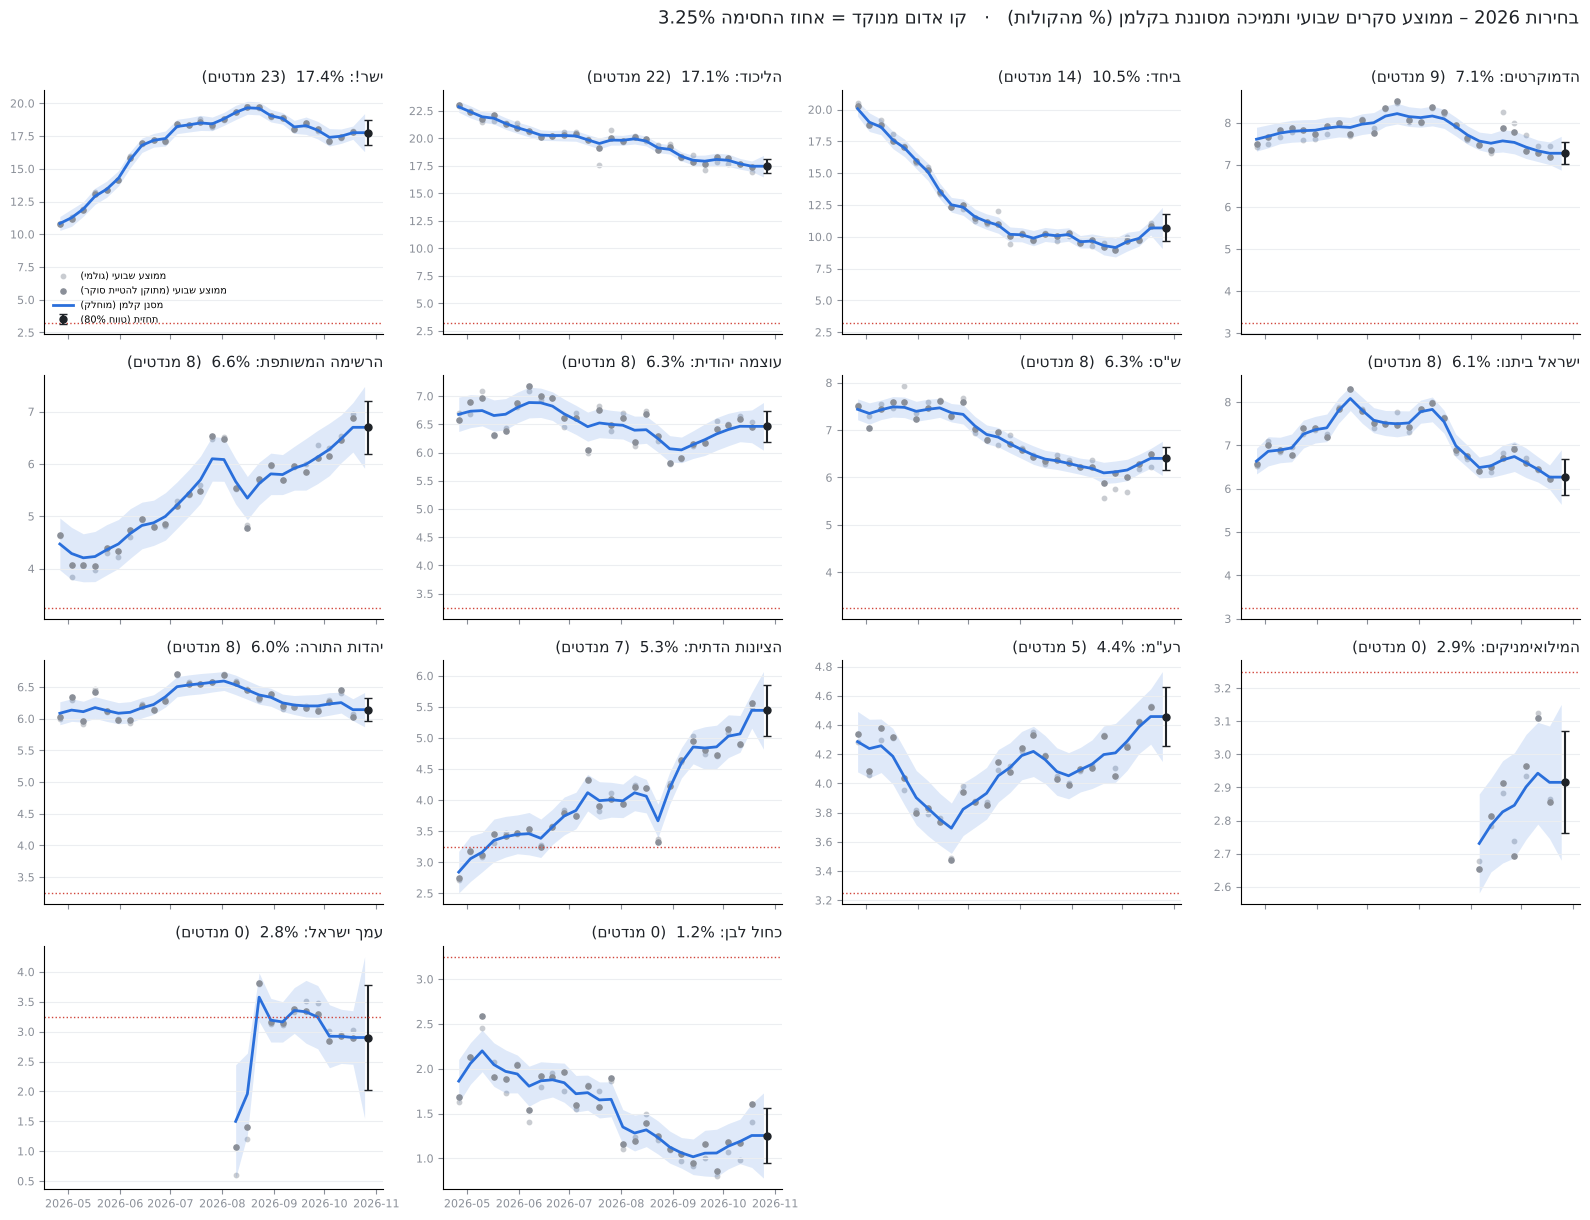

In [13]:
dates = weeks.start_time
order = list(res.index)
ncol = 4; nrow = int(np.ceil(len(order) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(16, 3.1 * nrow), sharex=True)
for ax, p in zip(axes.flat, order):
    d, r = paths[p], res.loc[p]
    ax.scatter(dates, d['raw'], s=10, color='#c9ccd1', label=h('ממוצע שבועי (גולמי)'), zorder=1)
    ax.scatter(dates, d['y'], s=14, color=MUTED, label=h('ממוצע שבועי (מתוקן להטיית סוקר)'), zorder=2)
    ax.fill_between(dates, d['s'] - 1.96 * np.sqrt(d['Ps']), d['s'] + 1.96 * np.sqrt(d['Ps']), color=ACC, alpha=.15, lw=0)
    ax.plot(dates, d['s'], color=ACC, lw=2, label=h('מסנן קלמן (מוחלק)'))
    ax.errorbar([ELECTION], [r.forecast], yerr=[[r.forecast - r.lo80], [r.hi80 - r.forecast]],
                fmt='o', color=INK, ms=5, capsize=3, label=h('תחזית (טווח 80%)'))
    ax.axhline(THRESH, color='#d1453b', lw=1, ls=':')
    ax.set_title(h(f"{HE[p]}: {r.forecast_norm:.1f}%  ({int(r.predicted_seats)} מנדטים)"), fontsize=11, color=INK, loc='right')
    ax.grid(axis='y', color='#eceef1'); ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(colors=MUTED, labelsize=8)
for ax in axes.flat[len(order):]:
    ax.axis('off')
axes.flat[0].legend(fontsize=7, frameon=False, loc='lower left')
fig.suptitle(h('בחירות 2026 – ממוצע סקרים שבועי ותמיכה מסוננת בקלמן (% מהקולות)   ·   קו אדום מנוקד = אחוז החסימה 3.25%'),
             fontsize=13, x=.99, ha='right', color=INK)
fig.tight_layout(rect=(0, 0, 1, .97))
fig.savefig(OUT + 'kalman_by_party.png', dpi=130)
plt.show()

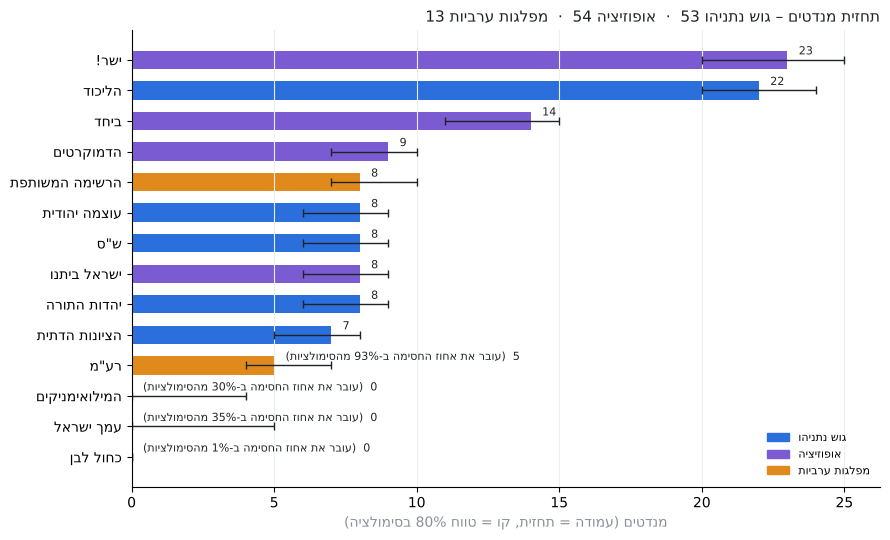

In [14]:
fig, ax = plt.subplots(figsize=(9, 5.5))
r = res.iloc[::-1]
col = ['#2a6fdb' if p in BLOCS['Netanyahu bloc'] else '#e08a1e' if p in BLOCS['Arab parties'] else '#7a5bd1' for p in r.index]
ax.barh([h(HE[p]) for p in r.index], r.predicted_seats, color=col, height=.6)
ax.errorbar(r.seats_median, range(len(r)), xerr=[r.seats_median - r.seats_lo80, r.seats_hi80 - r.seats_median],
            fmt='none', ecolor=INK, capsize=3, lw=1)
for i, (s, pp) in enumerate(zip(r.predicted_seats, r.p_pass_threshold)):
    ax.text(max(s, 0) + .4, i + .18, h(f"{s}" + (f"  (עובר את אחוז החסימה ב-{pp:.0%} מהסימולציות)" if pp < .97 else '')),
            fontsize=8, color=INK)
ax.set_xlabel(h('מנדטים (עמודה = תחזית, קו = טווח 80% בסימולציה)'), color=MUTED)
ax.set_title(h(f"תחזית מנדטים – גוש נתניהו {blocs.loc['Netanyahu bloc','predicted_seats']}  ·  "
               f"אופוזיציה {blocs.loc['Opposition (Jewish parties)','predicted_seats']}  ·  "
               f"מפלגות ערביות {blocs.loc['Arab parties','predicted_seats']}"), loc='right', fontsize=11, color=INK)
ax.legend(handles=[Patch(color='#2a6fdb', label=h('גוש נתניהו')), Patch(color='#7a5bd1', label=h('אופוזיציה')),
                   Patch(color='#e08a1e', label=h('מפלגות ערביות'))], frameon=False, fontsize=8, loc='lower right')
ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='x', color='#eceef1')
fig.tight_layout(); fig.savefig(OUT + 'seat_forecast.png', dpi=130)
plt.show()

## 8. Save outputs

In [15]:
res.round(3).to_csv(OUT + 'forecast_by_party.csv')
blocs.round(3).to_csv(OUT + 'forecast_by_bloc.csv')
house.round(2).to_csv(OUT + 'house_effects.csv')
tbl.round(2).to_csv(OUT + 'weekly_averages_house_adjusted.csv')
print('saved to', OUT)

saved to outputs/


## Limitations
- **House-effect centring** assumes the average pollster is right; Channel 14 / i24 (Filber, Direct Polls) show the Netanyahu bloc ~5–10 seats higher.
- **Seat → % conversion** only counts the wasted votes of parties the poll listed; tiny unlisted lists are ignored.
- **Surplus-vote agreements** (הסכמי עודפים) are not modelled and can move one seat.
- **Turnout** — especially Arab-sector turnout — is not in the polls' seat projections and is the largest unmodelled risk.
- Parties are treated as independent apart from the shared bloc error.